#### <i><b> Embeddings

##### <i><b> What is Embeddings?
- Embeddings are Numerical Vector representations of data. (E.g. words, sentence, images) that capture their meaning and relationship
- Similar items are located close together in the Vector Space, while unrelated items are farther apart.
- This Enables Semantic Similarity calculations using measures such as Cosine Similarity, allowing retrieval based on meaning rather than exact keyword matches.

<br>
<img src = "https://arize.com/wp-content/uploads/2022/06/blog-king-queen-embeddings.jpg" width = 500>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
words = ["Coding", "Computer", "Kitchen", "Carrot", "Sun"]

# Dummy Embedding with 3 Dimensions
embeddings = np.array([
    [0.90, 0.85, 0.80], # coding
    [0.95, 0.80, 0.75], # computer
    [0.30, 0.60, 0.40], # kitchen
    [0.25, 0.55, 0.35], # carrot
    [0.80, 0.20, 0.10]  # sun
])

In [3]:
L = ["Coding", "Computer", "Kitchen", "Carrot", "Sun"]
for index, value in enumerate(L, start = 10001):
    print(index, value)     

10001 Coding
10002 Computer
10003 Kitchen
10004 Carrot
10005 Sun


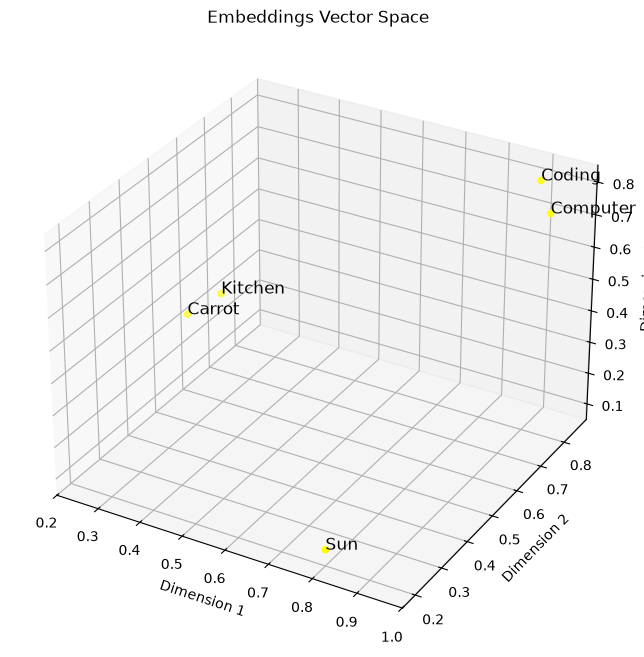

In [4]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot points
ax.scatter(
    embeddings[:, 0],
    embeddings[:, 1],
    embeddings[:, 2],
    c = "yellow"
)

# Add Labels
for index, word in enumerate(words):
    ax.text(
        embeddings[index, 0],
        embeddings[index, 1],
        embeddings[index, 2],
        word,
        fontsize = 12
    )

ax.set_title("Embeddings Vector Space")
ax.set_xlabel("Dimension 1")
ax.set_ylabel("Dimension 2")
ax.set_zlabel("Dimension 3")

plt.show()

##### <i><b> Cosine Similarity
- Cosine Similarity is a popular one for text embeddings.

<br>
<img src = "https://miro.medium.com/v2/resize:fit:1100/format:webp/1*iV-kVEuRcz_Qpl2AJxiKMA.jpeg" width = 500>

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

In [ ]:
similarity = cosine_similarity(embeddings)

df_similarity = pd.DataFrame(
    similarity,
    index = words,
    columns= words
) 

df_similarity.round(2)

,Coding,Computer,Kitchen,Carrot,Sun
Coding,1.00,1.00,0.96,0.94,0.79
Computer,1.00,1.00,0.94,0.93,0.83
Kitchen,0.96,0.94,1.00,1.00,0.62
Carrot,0.94,0.93,1.00,1.00,0.59
Sun,0.79,0.83,0.62,0.59,1.00


##### <i><b> Embeddings in Mistral LLM

In [1]:
import os
from dotenv import load_dotenv
from mistralai.client import Mistral

load_dotenv()
mistral = Mistral(api_key=os.environ['MISTRAL_API_KEY'])

In [8]:
documents = [
    "Cat", "Dog", "Bank", "School", "Engineer", "Salary"
]   

response = mistral.embeddings.create(
    model = "mistral-embed",
    inputs = documents
)

response

EmbeddingResponse(id='0f157f3f47ca44d299f0e5cb9acbfba5', object='list', model='mistral-embed', usage=UsageInfo(prompt_tokens=20, completion_tokens=0, total_tokens=20, prompt_audio_seconds=None, request_count=None, prompt_tokens_details=None, completion_tokens_details=None, service_tier=None, prompt_token_details=None), data=[EmbeddingResponseData(object='embedding', embedding=[0.028045654296875, 0.0301513671875, 0.07330322265625, 0.0154266357421875, 0.019287109375, 0.0075836181640625, 0.0290985107421875, -0.01244354248046875, -0.0096893310546875, -0.003353118896484375, -0.036651611328125, 0.043487548828125, -0.037872314453125, -0.00885009765625, -0.026824951171875, 0.020416259765625, 0.0189361572265625, -0.0005068778991699219, 0.00666046142578125, 0.01003265380859375, -0.00907135009765625, 0.0005340576171875, -0.032073974609375, 0.0160369873046875, -0.03680419921875, 0.0250701904296875, -0.0189361572265625, -0.039093017578125, -0.0264739990234375, -0.0173492431640625, -0.026123046875, 

In [9]:
response.data

[EmbeddingResponseData(object='embedding', embedding=[0.028045654296875, 0.0301513671875, 0.07330322265625, 0.0154266357421875, 0.019287109375, 0.0075836181640625, 0.0290985107421875, -0.01244354248046875, -0.0096893310546875, -0.003353118896484375, -0.036651611328125, 0.043487548828125, -0.037872314453125, -0.00885009765625, -0.026824951171875, 0.020416259765625, 0.0189361572265625, -0.0005068778991699219, 0.00666046142578125, 0.01003265380859375, -0.00907135009765625, 0.0005340576171875, -0.032073974609375, 0.0160369873046875, -0.03680419921875, 0.0250701904296875, -0.0189361572265625, -0.039093017578125, -0.0264739990234375, -0.0173492431640625, -0.026123046875, -0.0269927978515625, 0.0175323486328125, 0.04803466796875, 0.040313720703125, -0.0043182373046875, 0.022796630859375, -0.023834228515625, 0.026824951171875, -0.00266265869140625, -0.038055419921875, -0.037689208984375, -0.03155517578125, 0.02471923828125, 0.0214691162109375, -0.0173492431640625, -0.00907135009765625, -0.0134

In [10]:
embeddings = [data.embedding for data in response.data]
embeddings

[[0.028045654296875,
  0.0301513671875,
  0.07330322265625,
  0.0154266357421875,
  0.019287109375,
  0.0075836181640625,
  0.0290985107421875,
  -0.01244354248046875,
  -0.0096893310546875,
  -0.003353118896484375,
  -0.036651611328125,
  0.043487548828125,
  -0.037872314453125,
  -0.00885009765625,
  -0.026824951171875,
  0.020416259765625,
  0.0189361572265625,
  -0.0005068778991699219,
  0.00666046142578125,
  0.01003265380859375,
  -0.00907135009765625,
  0.0005340576171875,
  -0.032073974609375,
  0.0160369873046875,
  -0.03680419921875,
  0.0250701904296875,
  -0.0189361572265625,
  -0.039093017578125,
  -0.0264739990234375,
  -0.0173492431640625,
  -0.026123046875,
  -0.0269927978515625,
  0.0175323486328125,
  0.04803466796875,
  0.040313720703125,
  -0.0043182373046875,
  0.022796630859375,
  -0.023834228515625,
  0.026824951171875,
  -0.00266265869140625,
  -0.038055419921875,
  -0.037689208984375,
  -0.03155517578125,
  0.02471923828125,
  0.0214691162109375,
  -0.017349243

In [11]:
similarity = cosine_similarity(embeddings)
similarity

array([[1.        , 0.81637625, 0.73649507, 0.73275199, 0.68790756,
        0.6951583 ],
       [0.81637625, 1.        , 0.73907211, 0.74347502, 0.68930917,
        0.69179075],
       [0.73649507, 0.73907211, 1.        , 0.78047785, 0.72623023,
        0.74241057],
       [0.73275199, 0.74347502, 0.78047785, 1.        , 0.73498707,
        0.74074002],
       [0.68790756, 0.68930917, 0.72623023, 0.73498707, 1.        ,
        0.71507494],
       [0.6951583 , 0.69179075, 0.74241057, 0.74074002, 0.71507494,
        1.        ]])

In [12]:
df_similarity = pd.DataFrame(
    similarity,
    index = documents,
    columns= documents
)

df_similarity.round(2)

,Cat,Dog,Bank,School,Engineer,Salary
Cat,1.00,0.82,0.74,0.73,0.69,0.70
Dog,0.82,1.00,0.74,0.74,0.69,0.69
Bank,0.74,0.74,1.00,0.78,0.73,0.74
School,0.73,0.74,0.78,1.00,0.73,0.74
Engineer,0.69,0.69,0.73,0.73,1.00,0.72
Salary,0.70,0.69,0.74,0.74,0.72,1.00
